In [8]:
import os
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from compcats.models import resnet18_imagenet1kv1, resnet50_imagenet1kv2
from compcats.datasets.fmri import nsd
from compcats.utils import model_utils

import main_analysis as ma
import paths

RESULTS_DIR = 'results'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/vss25_presentation'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
KONKLE_LOCALIZER_DIR = paths.KONKLE_LOCALIZER_DIR

froi = 'FFA'
tthreshold = 7
model_localizer = 'grillspector'
subject1 = 2
subject2 = 5
subset = 515

plot_dir = f'{PLOTS_DIR}/schematic'
os.makedirs(plot_dir, exist_ok=True)

# Load ResNet50-ImageNet
# model = resnet18_imagenet1kv1.get_model()
model = resnet50_imagenet1kv2.get_model()
model.eval()

In [7]:
plot_dir = f'{PLOTS_DIR}/v2/schematic/category_contrast'
os.makedirs(plot_dir, exist_ok=True)

savefig = True

model_list = [
    'alexnetimagenet1kv1',
    'resnet50imagenet1kv2',
    'resnet50openaiclip',
    'vitb32imagenet1kv1',
    'vitl14openaiclip'
] 
for froi in ['FFA', 'PPA', 'EBA']:
    if froi == 'FFA':
        pref_category = 'faces'
    elif froi == 'PPA':
        pref_category = 'scenes'
    elif froi == 'EBA':
        pref_category = 'bodies'
    for model_name in model_list:
        model = ma.get_model(model_name)
        model.eval()
        print(f'Processing model: {model.name}, froi: {froi}')
        # Konkle FBSO
        ko_acts = model_utils.get_dataset_activations(
            MODELS_DIR, KONKLE_LOCALIZER_DIR, \
            model, ma.get_froi_models_layers(froi, froi)[model.name],
            dataset='localizer', localizer_type='konkle', \
            froi=froi, tthreshold=tthreshold, \
            froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR
        )
        ko_acts_univariate = {k: v.mean(axis=-1) for k, v in ko_acts.items()}

        # Prepare data for plotting with z-scoring
        categories = list(ko_acts_univariate.keys())

        # Reorder categories and rename 'places' to 'scenes'
        # category_mapping = {'places': 'scenes', 'scrambledobjects': 'scrambled objects'}
        # ordered_categories = ['faces', 'bodies', 'places', 'objects', 'characters', 'scrambledobjects']
        ordered_categories = ['faces', 'scenes', 'bodies', 'objects']
        # display_names = [category_mapping.get(cat, cat) for cat in ordered_categories]

        # Get all activations and compute overall mean and std for z-scoring
        all_vals = torch.cat([ko_acts_univariate[cat] for cat in categories])
        overall_mean = all_vals.mean().cpu().numpy()
        overall_std = all_vals.std().cpu().numpy()

        # Compute z-scored medians and SEMs for the ordered categories
        z_medians = [torch.median(ko_acts_univariate[cat]).cpu().numpy() for cat in ordered_categories]
        z_sems = [torch.std(ko_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(ko_acts_univariate[cat])) for cat in ordered_categories]
        z_sems = None
        z_medians = [(torch.median(ko_acts_univariate[cat]).cpu().numpy() - overall_mean) / overall_std for cat in ordered_categories]
        z_sems = [(torch.std(ko_acts_univariate[cat]).cpu().numpy() / np.sqrt(len(ko_acts_univariate[cat]))) / overall_std for cat in ordered_categories]

        # Set up the plot
        plt.figure(figsize=(5, 5), dpi=300)
        # Add horizontal line at z=0
        plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=0.75)
        bar_positions = np.arange(len(ordered_categories))
        # bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=3, 
        #                color=['coral' if cat == pref_category else 'skyblue' for cat in ordered_categories])
        bars = plt.bar(bar_positions, z_medians, yerr=z_sems, capsize=0, color='gray', error_kw={'linewidth': 1})

        # Highlight the preferred category
        for i, cat in enumerate(ordered_categories):
            if cat == pref_category:
                # bars[i].set_color('coral')
                bars[i].set_color('red')
                # bars[i].set_edgecolor('black')
                # bars[i].set_linewidth(1)


        # Add labels and title
        # Remove top and right spines
        plt.gca().spines['top'].set_visible(False)
        plt.gca().spines['right'].set_visible(False)
        plt.gca().spines['left'].set_position(('outward', 5))
        plt.gca().spines['bottom'].set_position(('outward', 5))
        # plt.xlabel('Categories', fontsize=12)
        # plt.ylabel('Z-scored Unit-averaged Activations', fontsize=12)
        # plt.title(f'ResNet50 z-scored Univariate Responses of face-selective units', fontsize=14)
        # plt.xticks(bar_positions, [cat.capitalize() for cat in ordered_categories], rotation=45)
        # plt.yticks([0, 1, 2], [0, 1, 2], fontsize=12)
        plt.yticks([-1.5, -0.75, 0, 0.75, 1.5, 2.25])
        # plt.ylim(-0.75, 2.3)
        plt.ylim(-1.5, 2.3075)
        plt.tick_params(axis='y', labelleft=False)
        # plt.gca().spines['left'].set_bounds(-0.75, 2.25)
        plt.gca().spines['left'].set_bounds(-1.5, 2.25)
        # plt.yticks([0, 1], [0, 1], fontsize=12)
        plt.xticks(bar_positions, [])
        plt.gca().spines['bottom'].set_bounds(np.arange(len(ordered_categories))[0], np.arange(len(ordered_categories))[-1])
        plt.tight_layout()

        # plt.savefig(f'{plot_dir}/model_localization_contrast_konkle_nozscore.pdf', dpi=300, bbox_inches='tight', transparent=True)
        # plt.savefig(f'{plot_dir}/rn18imgnet_localization_contrast_konkle_zscore.png', dpi=300, bbox_inches='tight', transparent=True)
        if savefig:
            plt.savefig(f'{plot_dir}/{model.name}_{froi}_localization_contrast_konkle_zscore.png', dpi=300, bbox_inches='tight', transparent=True)
        else:
            plt.show()
        plt.close()

Processing model: alexnetimagenet1kv1, froi: FFA
Processing model: resnet50imagenet1kv2, froi: FFA
Processing model: resnet50openaiclip, froi: FFA
Processing model: vitb32imagenet1kv1, froi: FFA
Processing model: vitl14openaiclip, froi: FFA
Processing model: alexnetimagenet1kv1, froi: PPA
Processing model: resnet50imagenet1kv2, froi: PPA
Processing model: resnet50openaiclip, froi: PPA
Processing model: vitb32imagenet1kv1, froi: PPA
Processing model: vitl14openaiclip, froi: PPA
Processing model: alexnetimagenet1kv1, froi: EBA
Processing model: resnet50imagenet1kv2, froi: EBA
Processing model: resnet50openaiclip, froi: EBA
Processing model: vitb32imagenet1kv1, froi: EBA
Processing model: vitl14openaiclip, froi: EBA


In [9]:
model_data_raw = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, ma.get_froi_models_layers(froi, froi)[model.name],
    dataset='nsd', subset=subset, froi=froi, tthreshold=tthreshold,
    froi_localizer=model_localizer, froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, device='cpu'
)
print(model_data_raw.shape)
model_data = model_data_raw.mean(axis=-1).cpu().numpy()
model_data_zscore = (model_data - np.mean(model_data)) / np.std(model_data)
model_data_minmax = (model_data - np.min(model_data)) / (np.max(model_data) - np.min(model_data))

subject_data1_raw, _ = nsd.get_betas(
    NSD_DIR, subject1, froi=froi, tthreshold=tthreshold, subset=subset, voxels=True
)
print(subject_data1_raw.shape)
subject_data1 = subject_data1_raw.mean(axis=-1).cpu().numpy()
subject_data1_zscore = (subject_data1 - np.mean(subject_data1)) / np.std(subject_data1)
subject_data1_minmax = (subject_data1 - np.min(subject_data1)) / (np.max(subject_data1) - np.min(subject_data1))

subject_data2_raw, _ = nsd.get_betas(
    NSD_DIR, subject2, froi=froi, tthreshold=tthreshold, subset=subset, voxels=True
)
print(subject_data2_raw.shape)
subject_data2 = subject_data2_raw.mean(axis=-1).cpu().numpy()
subject_data2_zscore = (subject_data2 - np.mean(subject_data2)) / np.std(subject_data2)
subject_data2_minmax = (subject_data2 - np.min(subject_data2)) / (np.max(subject_data2) - np.min(subject_data2))

print(subject_data1_zscore.min(), subject_data1_zscore.max())
print(subject_data2_zscore.min(), subject_data2_zscore.max())
print(model_data_zscore.min(), model_data_zscore.max())
print(np.corrcoef(subject_data1_zscore, subject_data2_zscore)[0, 1])
print(np.corrcoef(subject_data1_zscore, model_data_zscore)[0, 1])
print(np.corrcoef(subject_data2_zscore, model_data_zscore)[0, 1])

print(subject_data1_minmax.min(), subject_data1_minmax.max())
print(subject_data2_minmax.min(), subject_data2_minmax.max())
print(model_data_minmax.min(), model_data_minmax.max())
print(np.corrcoef(subject_data1_minmax, subject_data2_minmax)[0, 1])
print(np.corrcoef(subject_data1_minmax, model_data_minmax)[0, 1])

torch.Size([515, 729])
torch.Size([515, 218])
torch.Size([515, 271])
-2.5090816 2.9361813
-1.8164136 3.058831
-1.1127945 6.6847787
0.7529481696809944
0.6397014569266722
0.6051500903498032
0.0 1.0
0.0 1.0
0.0 1.0
0.7529481703152254
0.6397014517760378


In [10]:
raster_subject1 = subject_data1_raw.T.cpu().numpy()
# Z-score the raster data individually for each voxel
raster_subject1_zscored = (raster_subject1 - np.mean(raster_subject1, axis=1, keepdims=True)) / np.std(raster_subject1, axis=1, keepdims=True)
raster_subject2 = subject_data2_raw.T.cpu().numpy()
# Z-score the raster data individually for each voxel
raster_subject2_zscored = (raster_subject2 - np.mean(raster_subject2, axis=1, keepdims=True)) / np.std(raster_subject2, axis=1, keepdims=True)
raster_model = model_data_raw.T.cpu().numpy()
# Z-score the raster data individually for each unit
raster_model_zscored = (raster_model - np.mean(raster_model, axis=1, keepdims=True)) / np.std(raster_model, axis=1, keepdims=True)

print(raster_subject1.min(), raster_subject2.min(), raster_model.min())
print(raster_subject1.max(), raster_subject2.max(), raster_model.max())

print(raster_subject1_zscored.shape, raster_subject2_zscored.shape, raster_model_zscored.shape)
print(raster_subject1_zscored.mean(axis=0).min(), raster_subject2_zscored.mean(axis=0).min(), raster_model_zscored.mean(axis=0).min())
print(raster_subject1_zscored.mean(axis=0).max(), raster_subject2_zscored.mean(axis=0).max(), raster_model_zscored.mean(axis=0).max())

-2.8279626 -3.6483316 0.0
3.3137915 4.9820795 37.317192
(218, 515) (271, 515) (729, 515)
-1.6160469 -1.1069747 -0.21370313
1.8767124 1.8452646 1.3191323


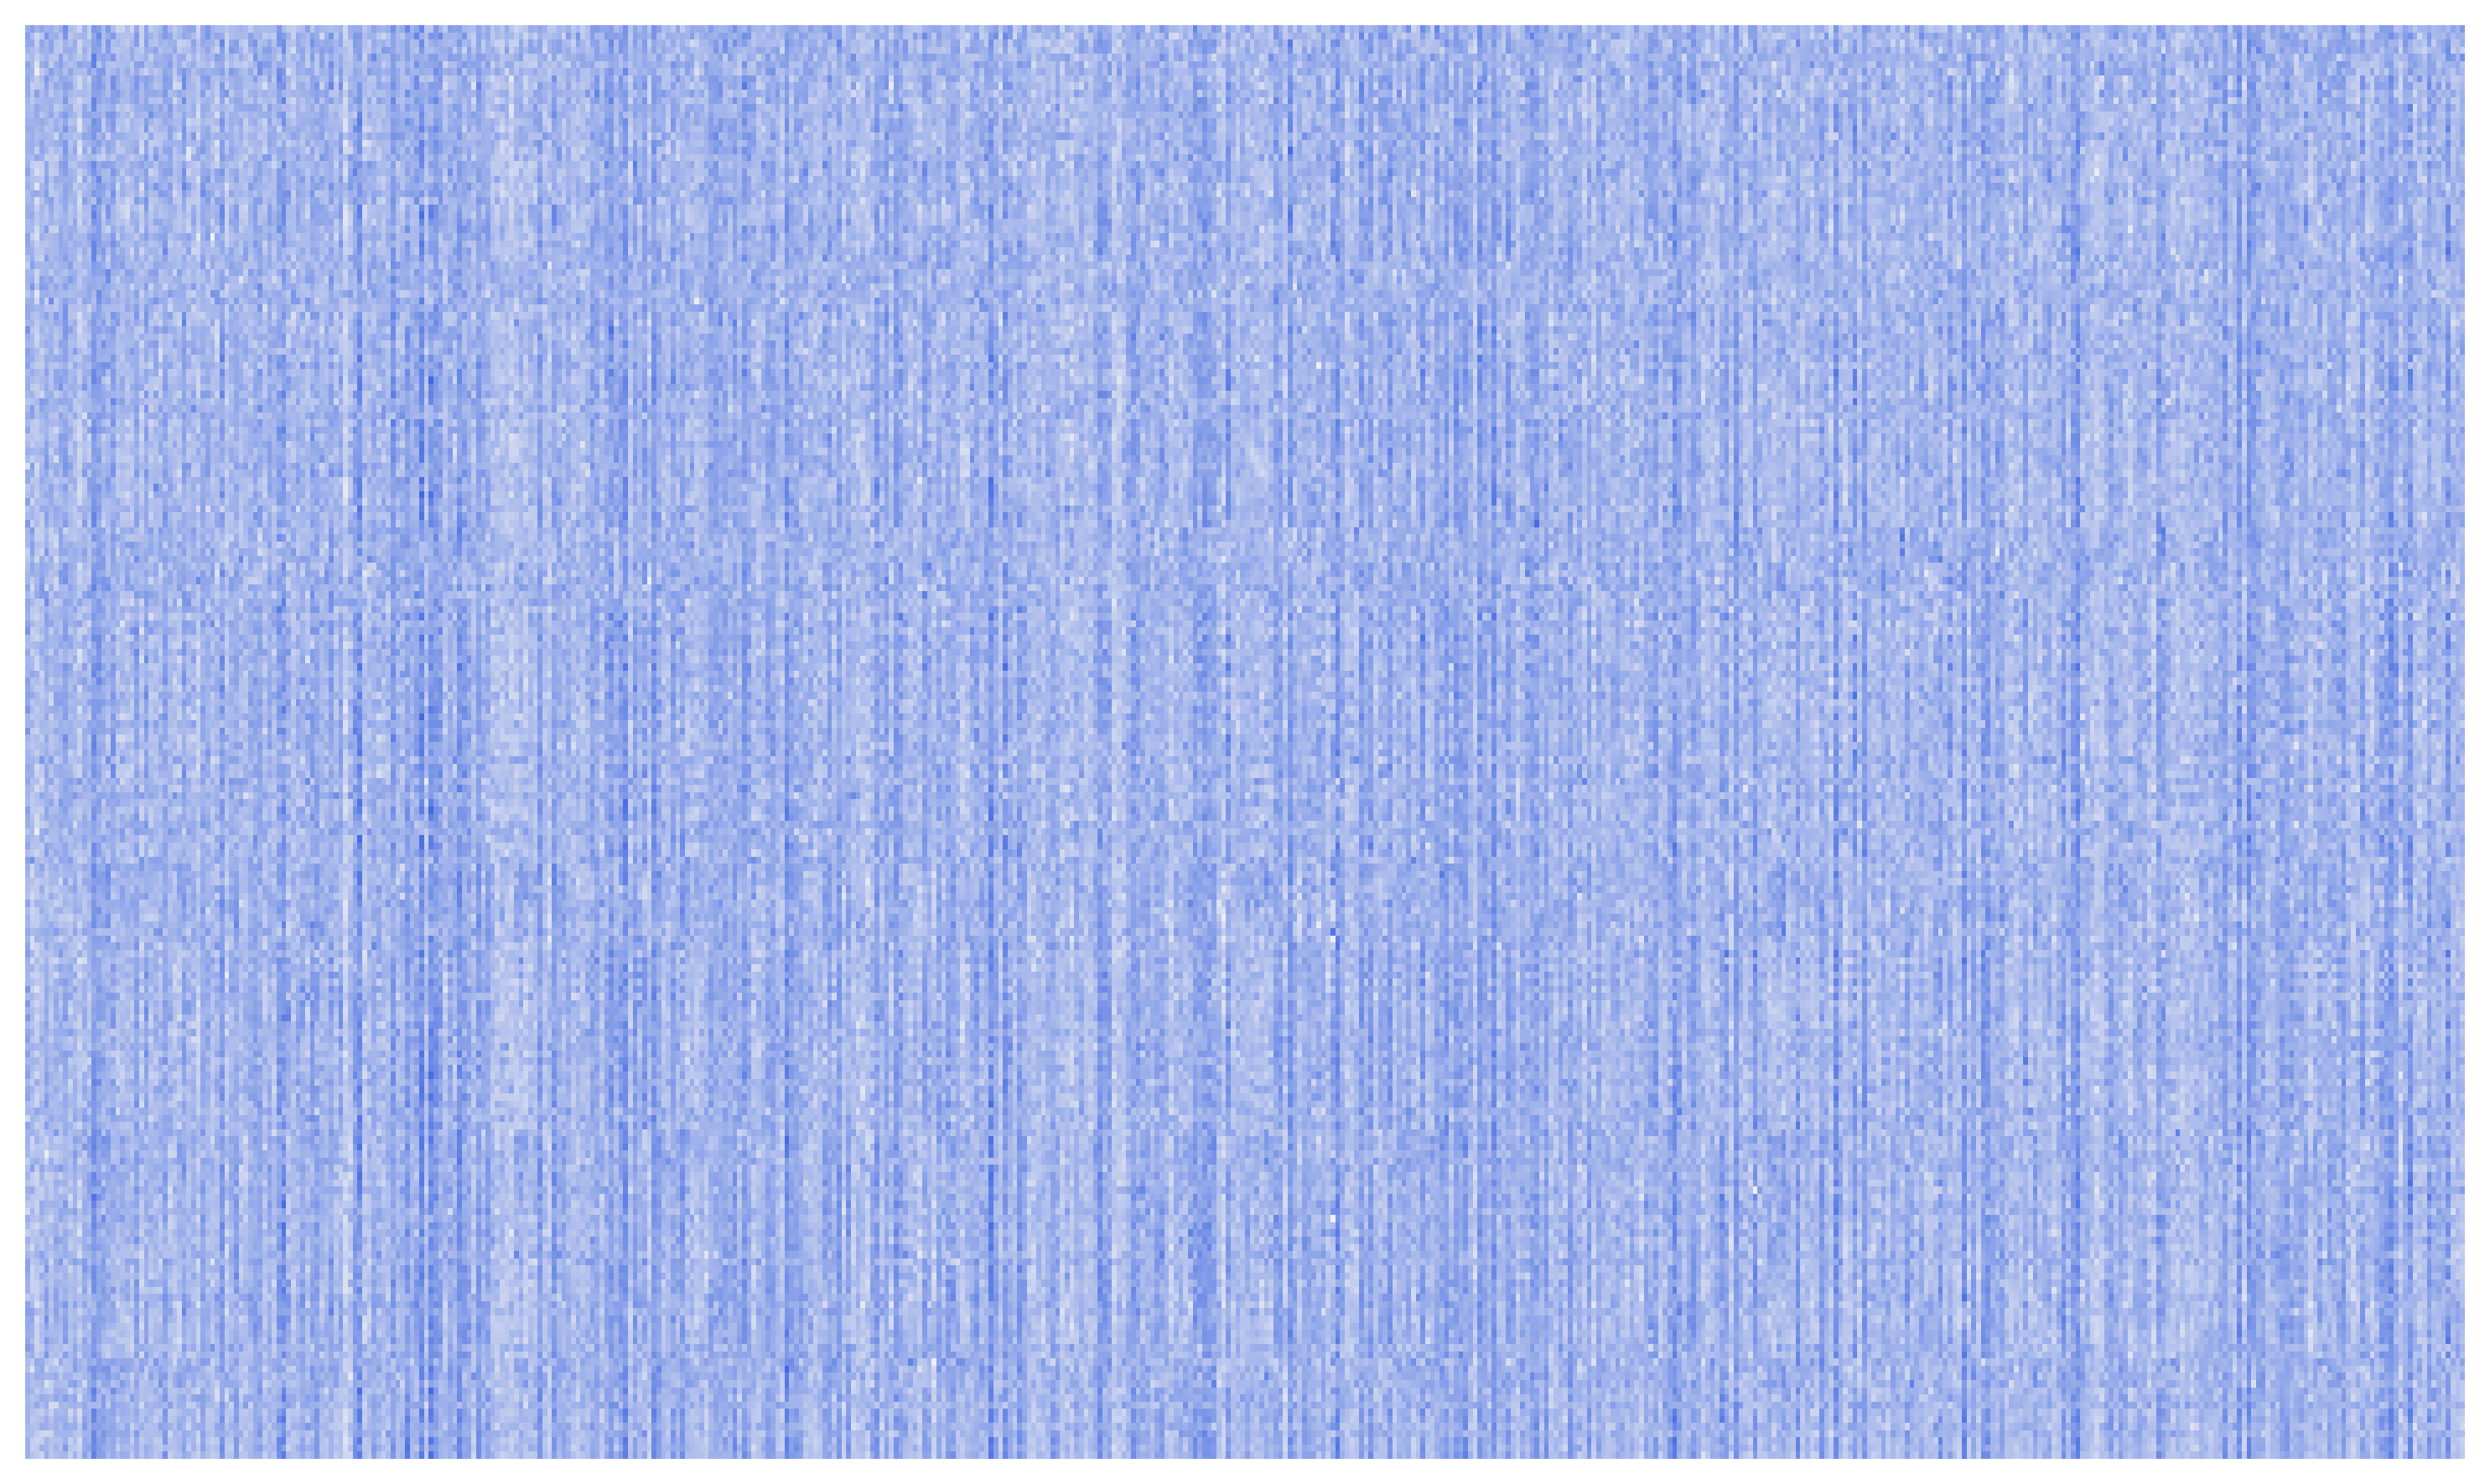

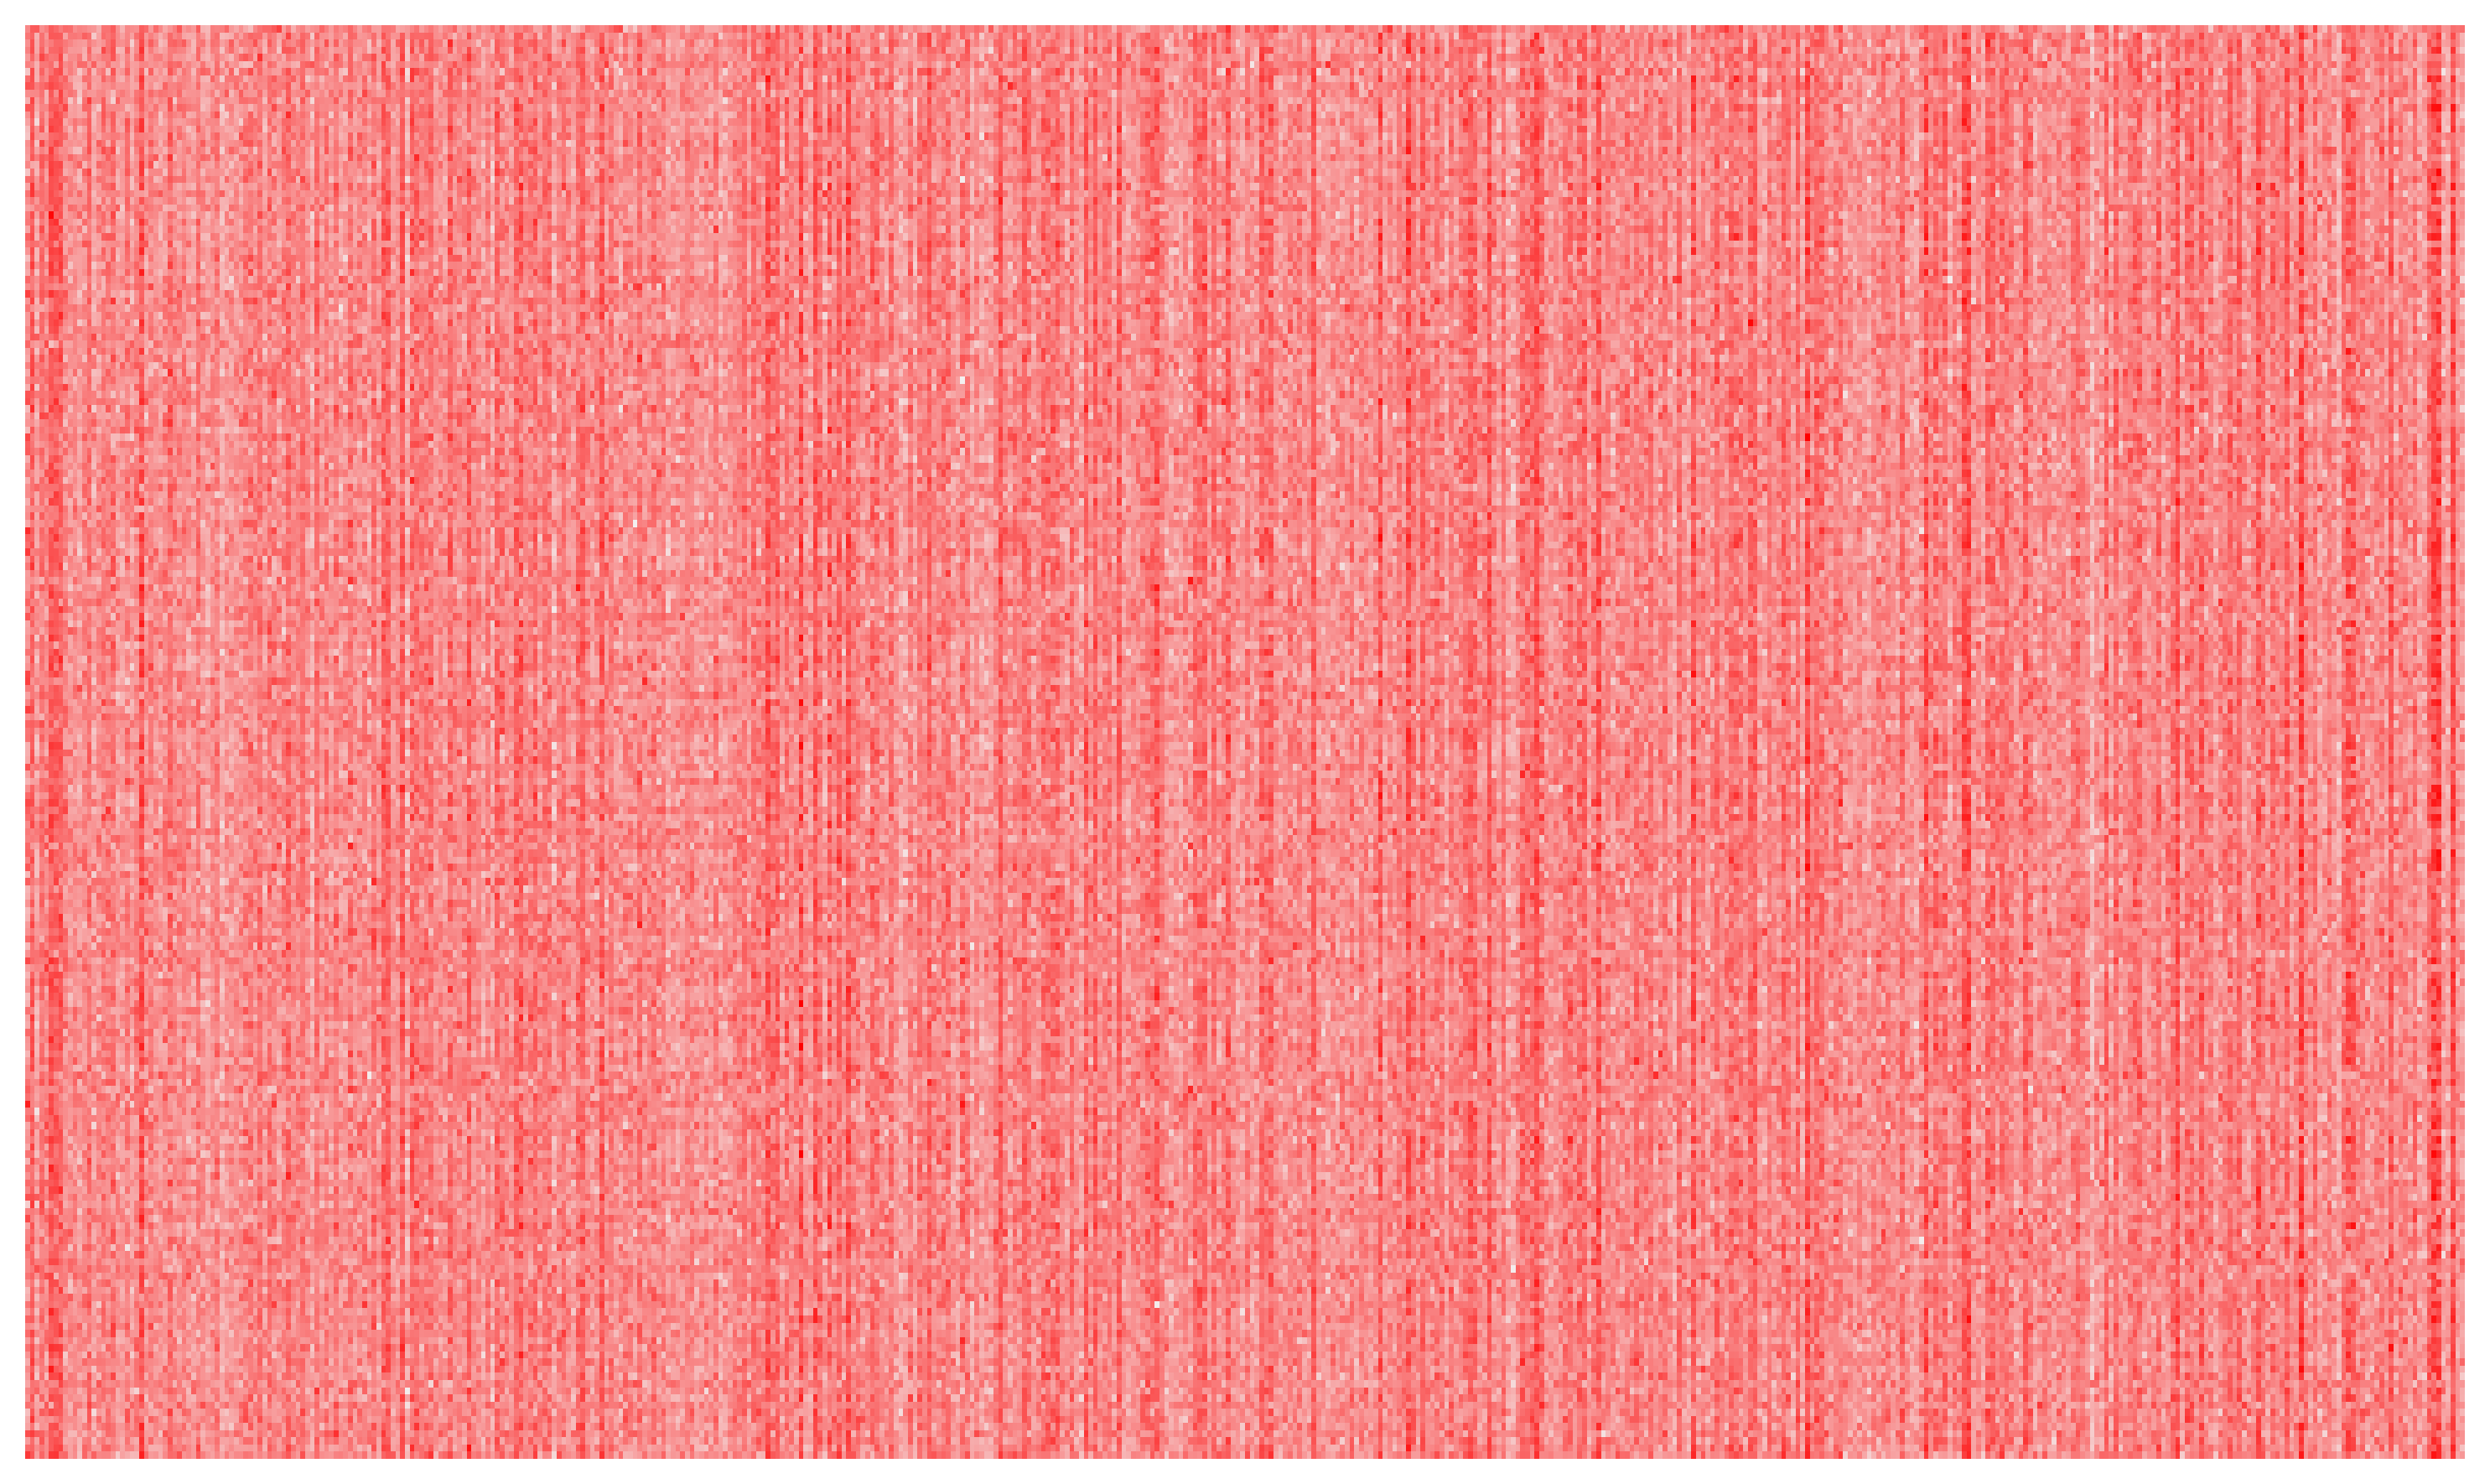

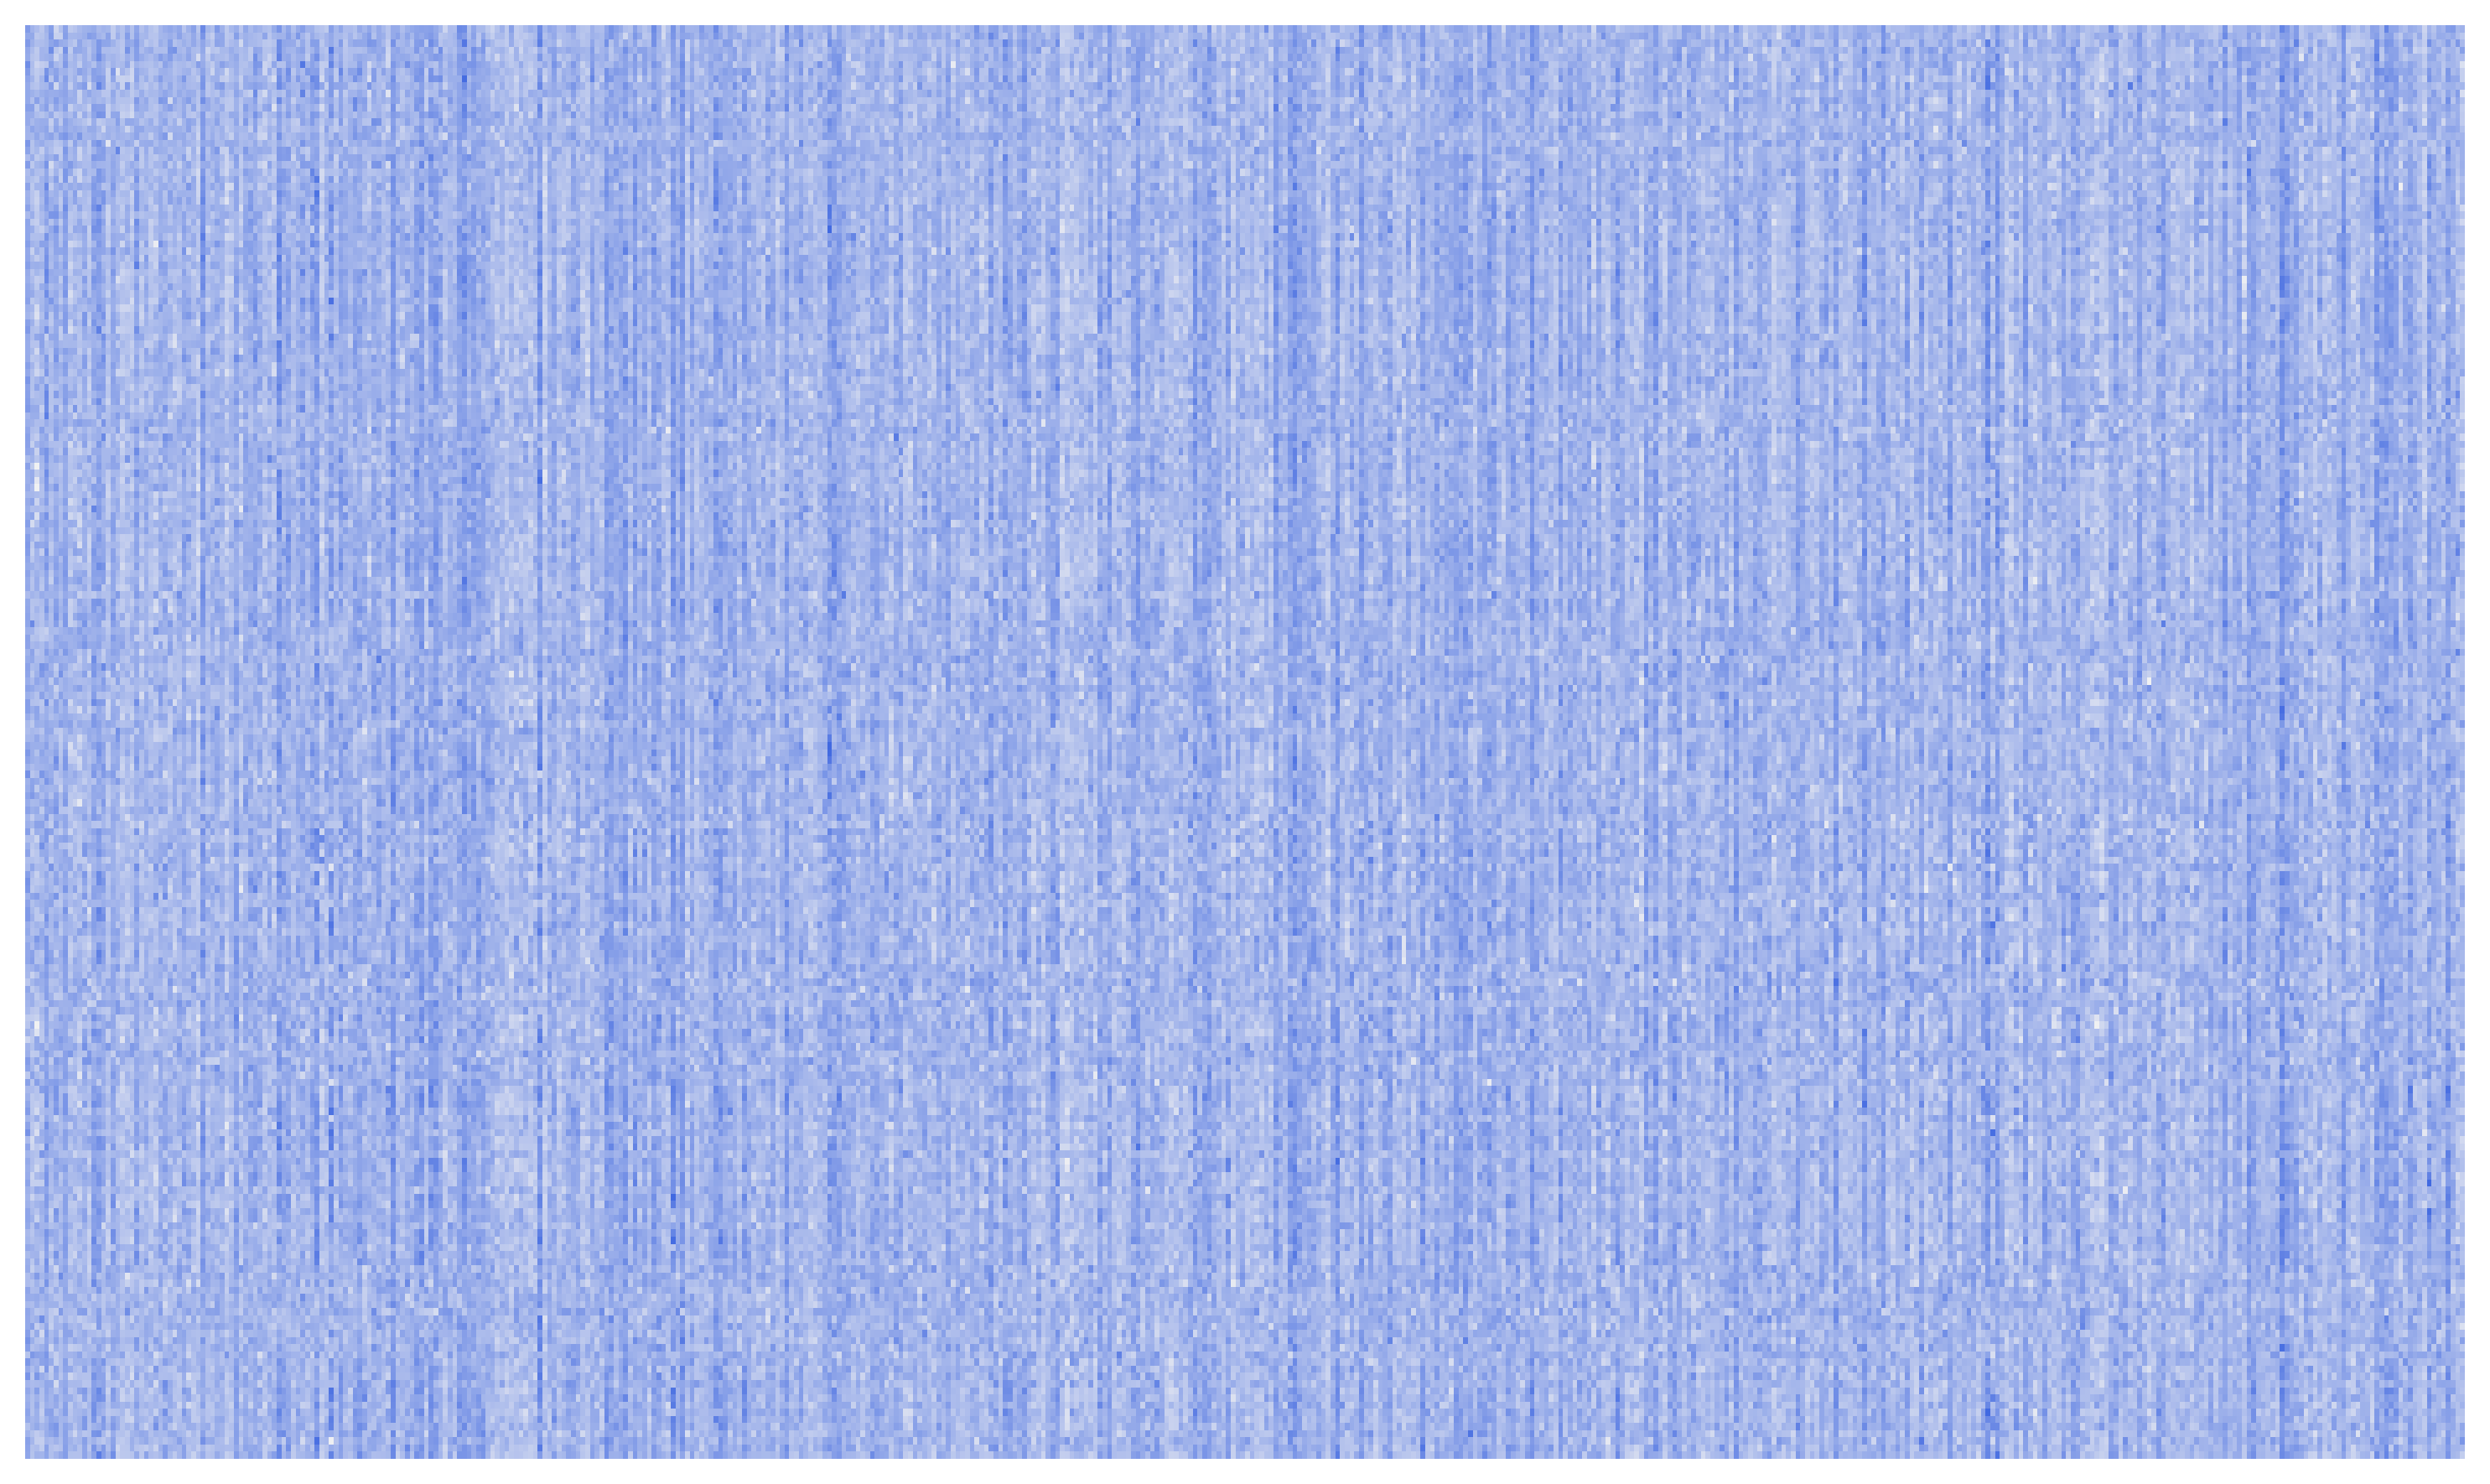

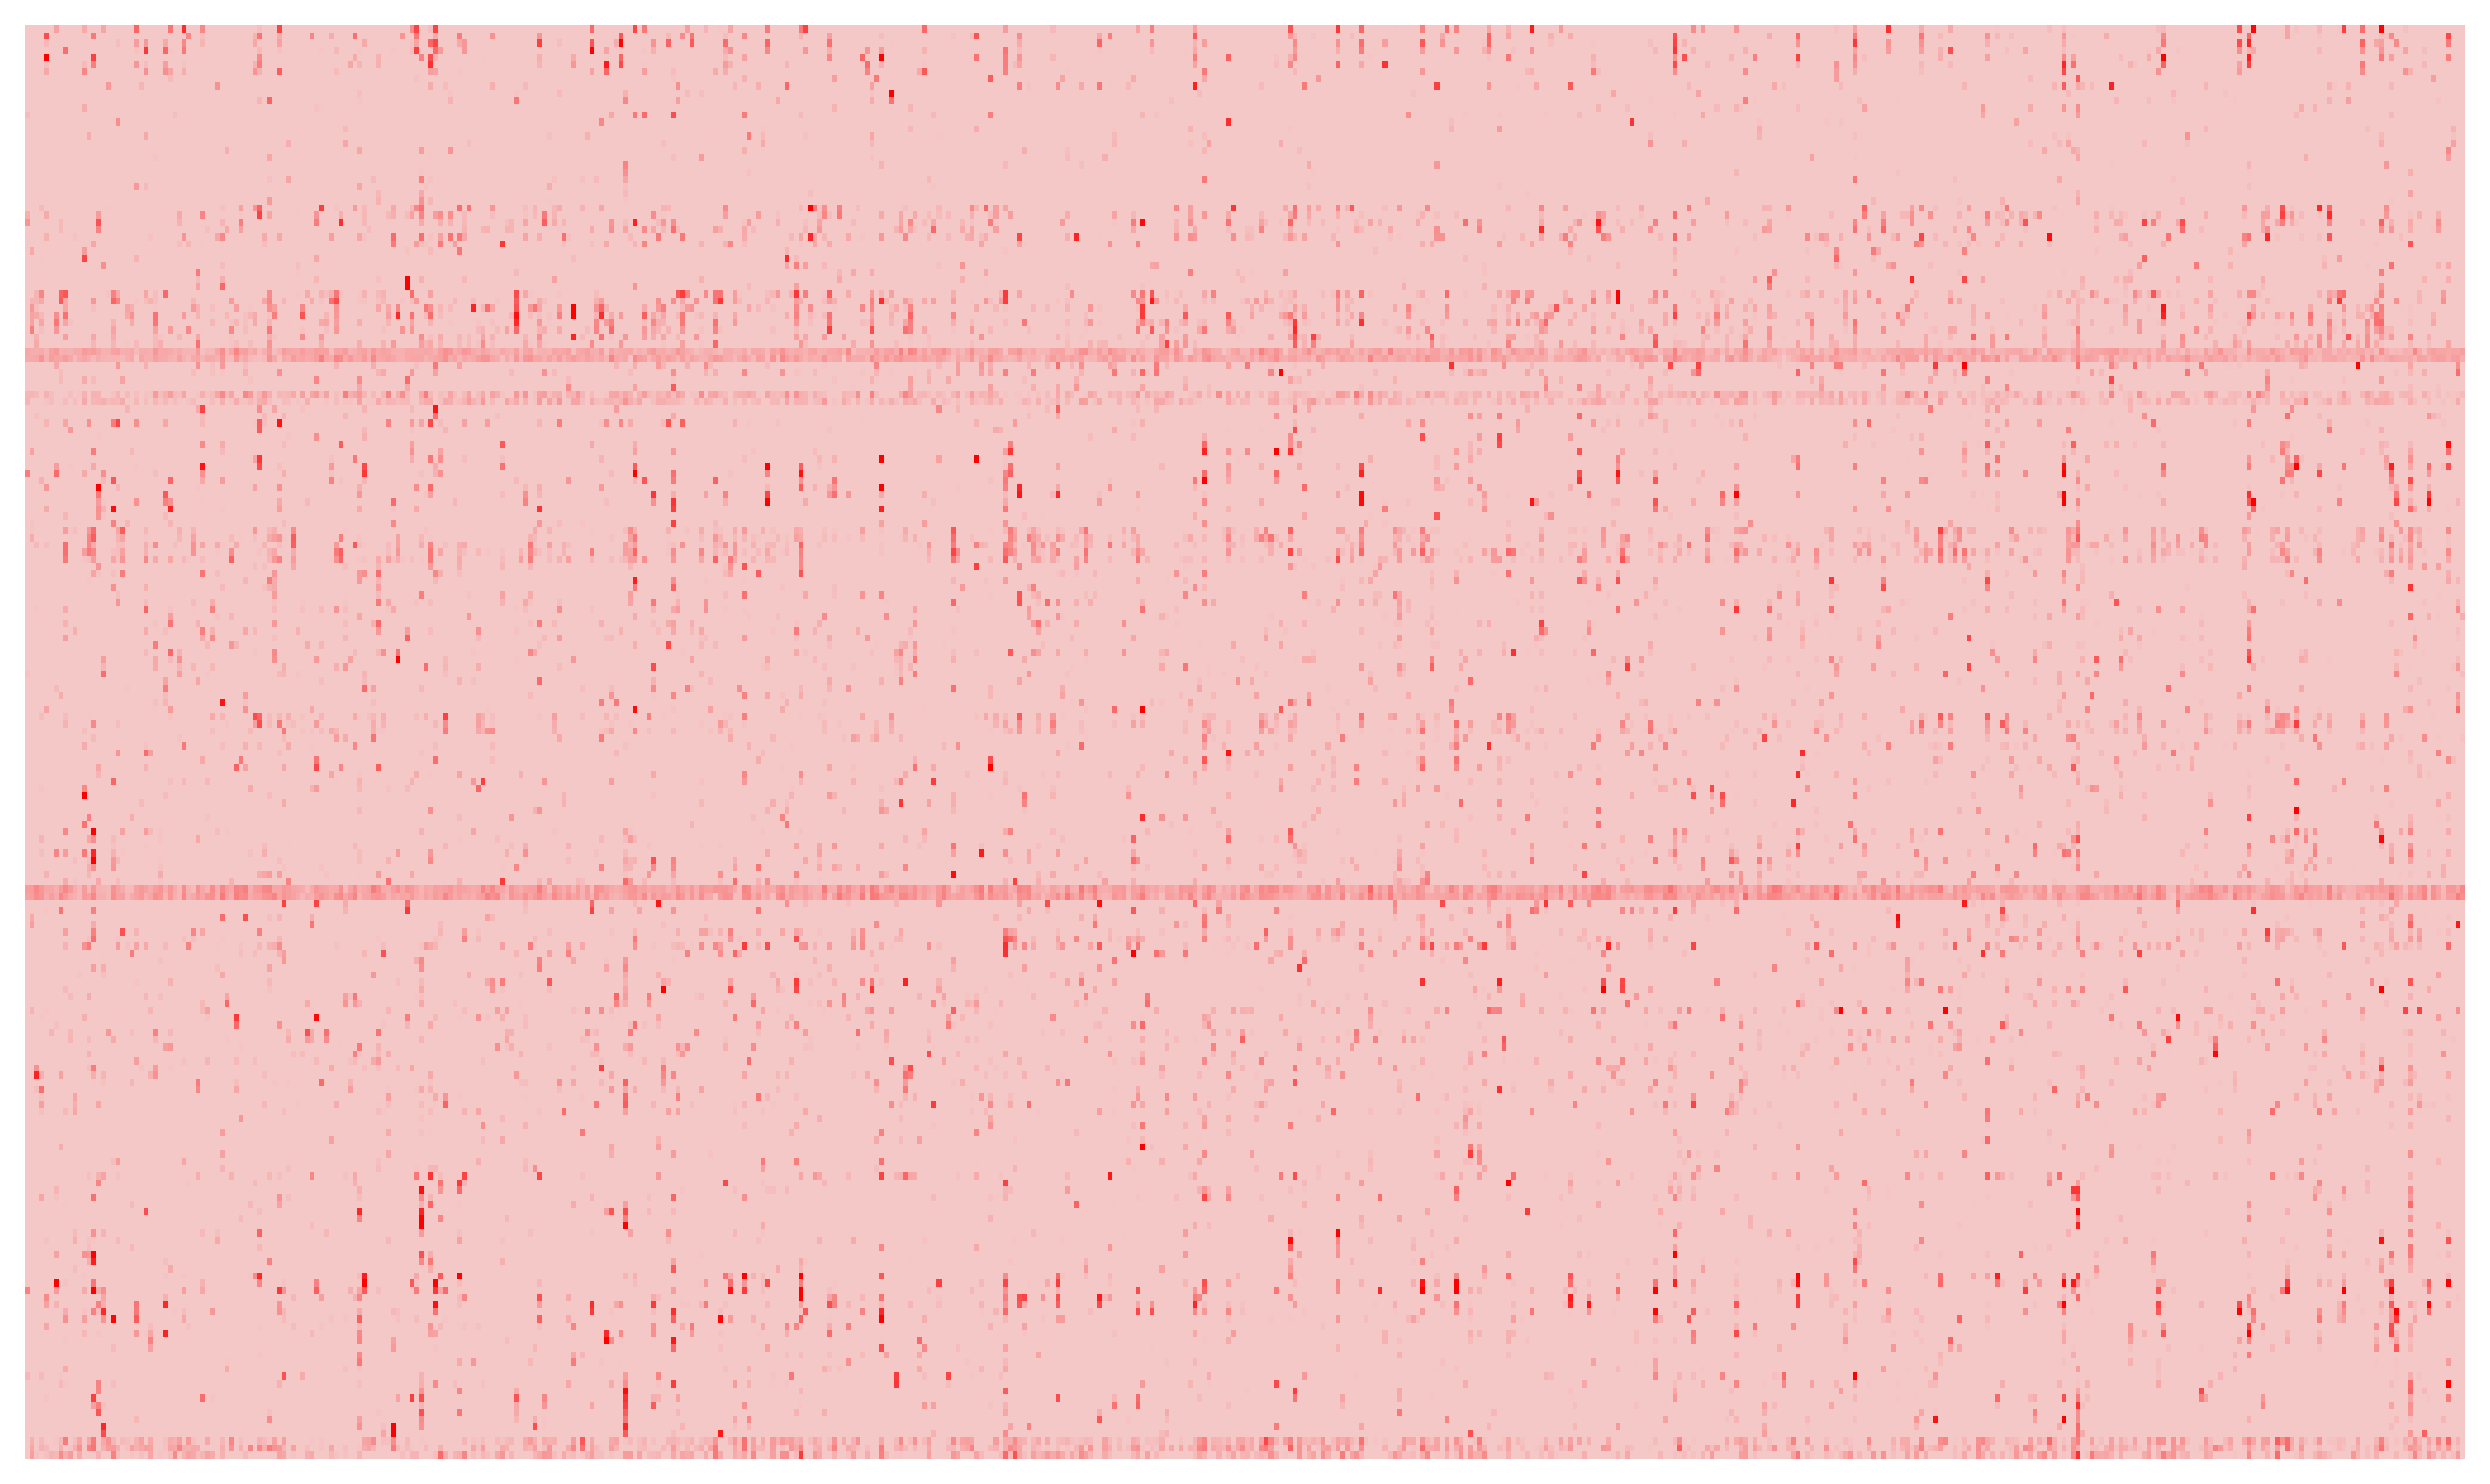

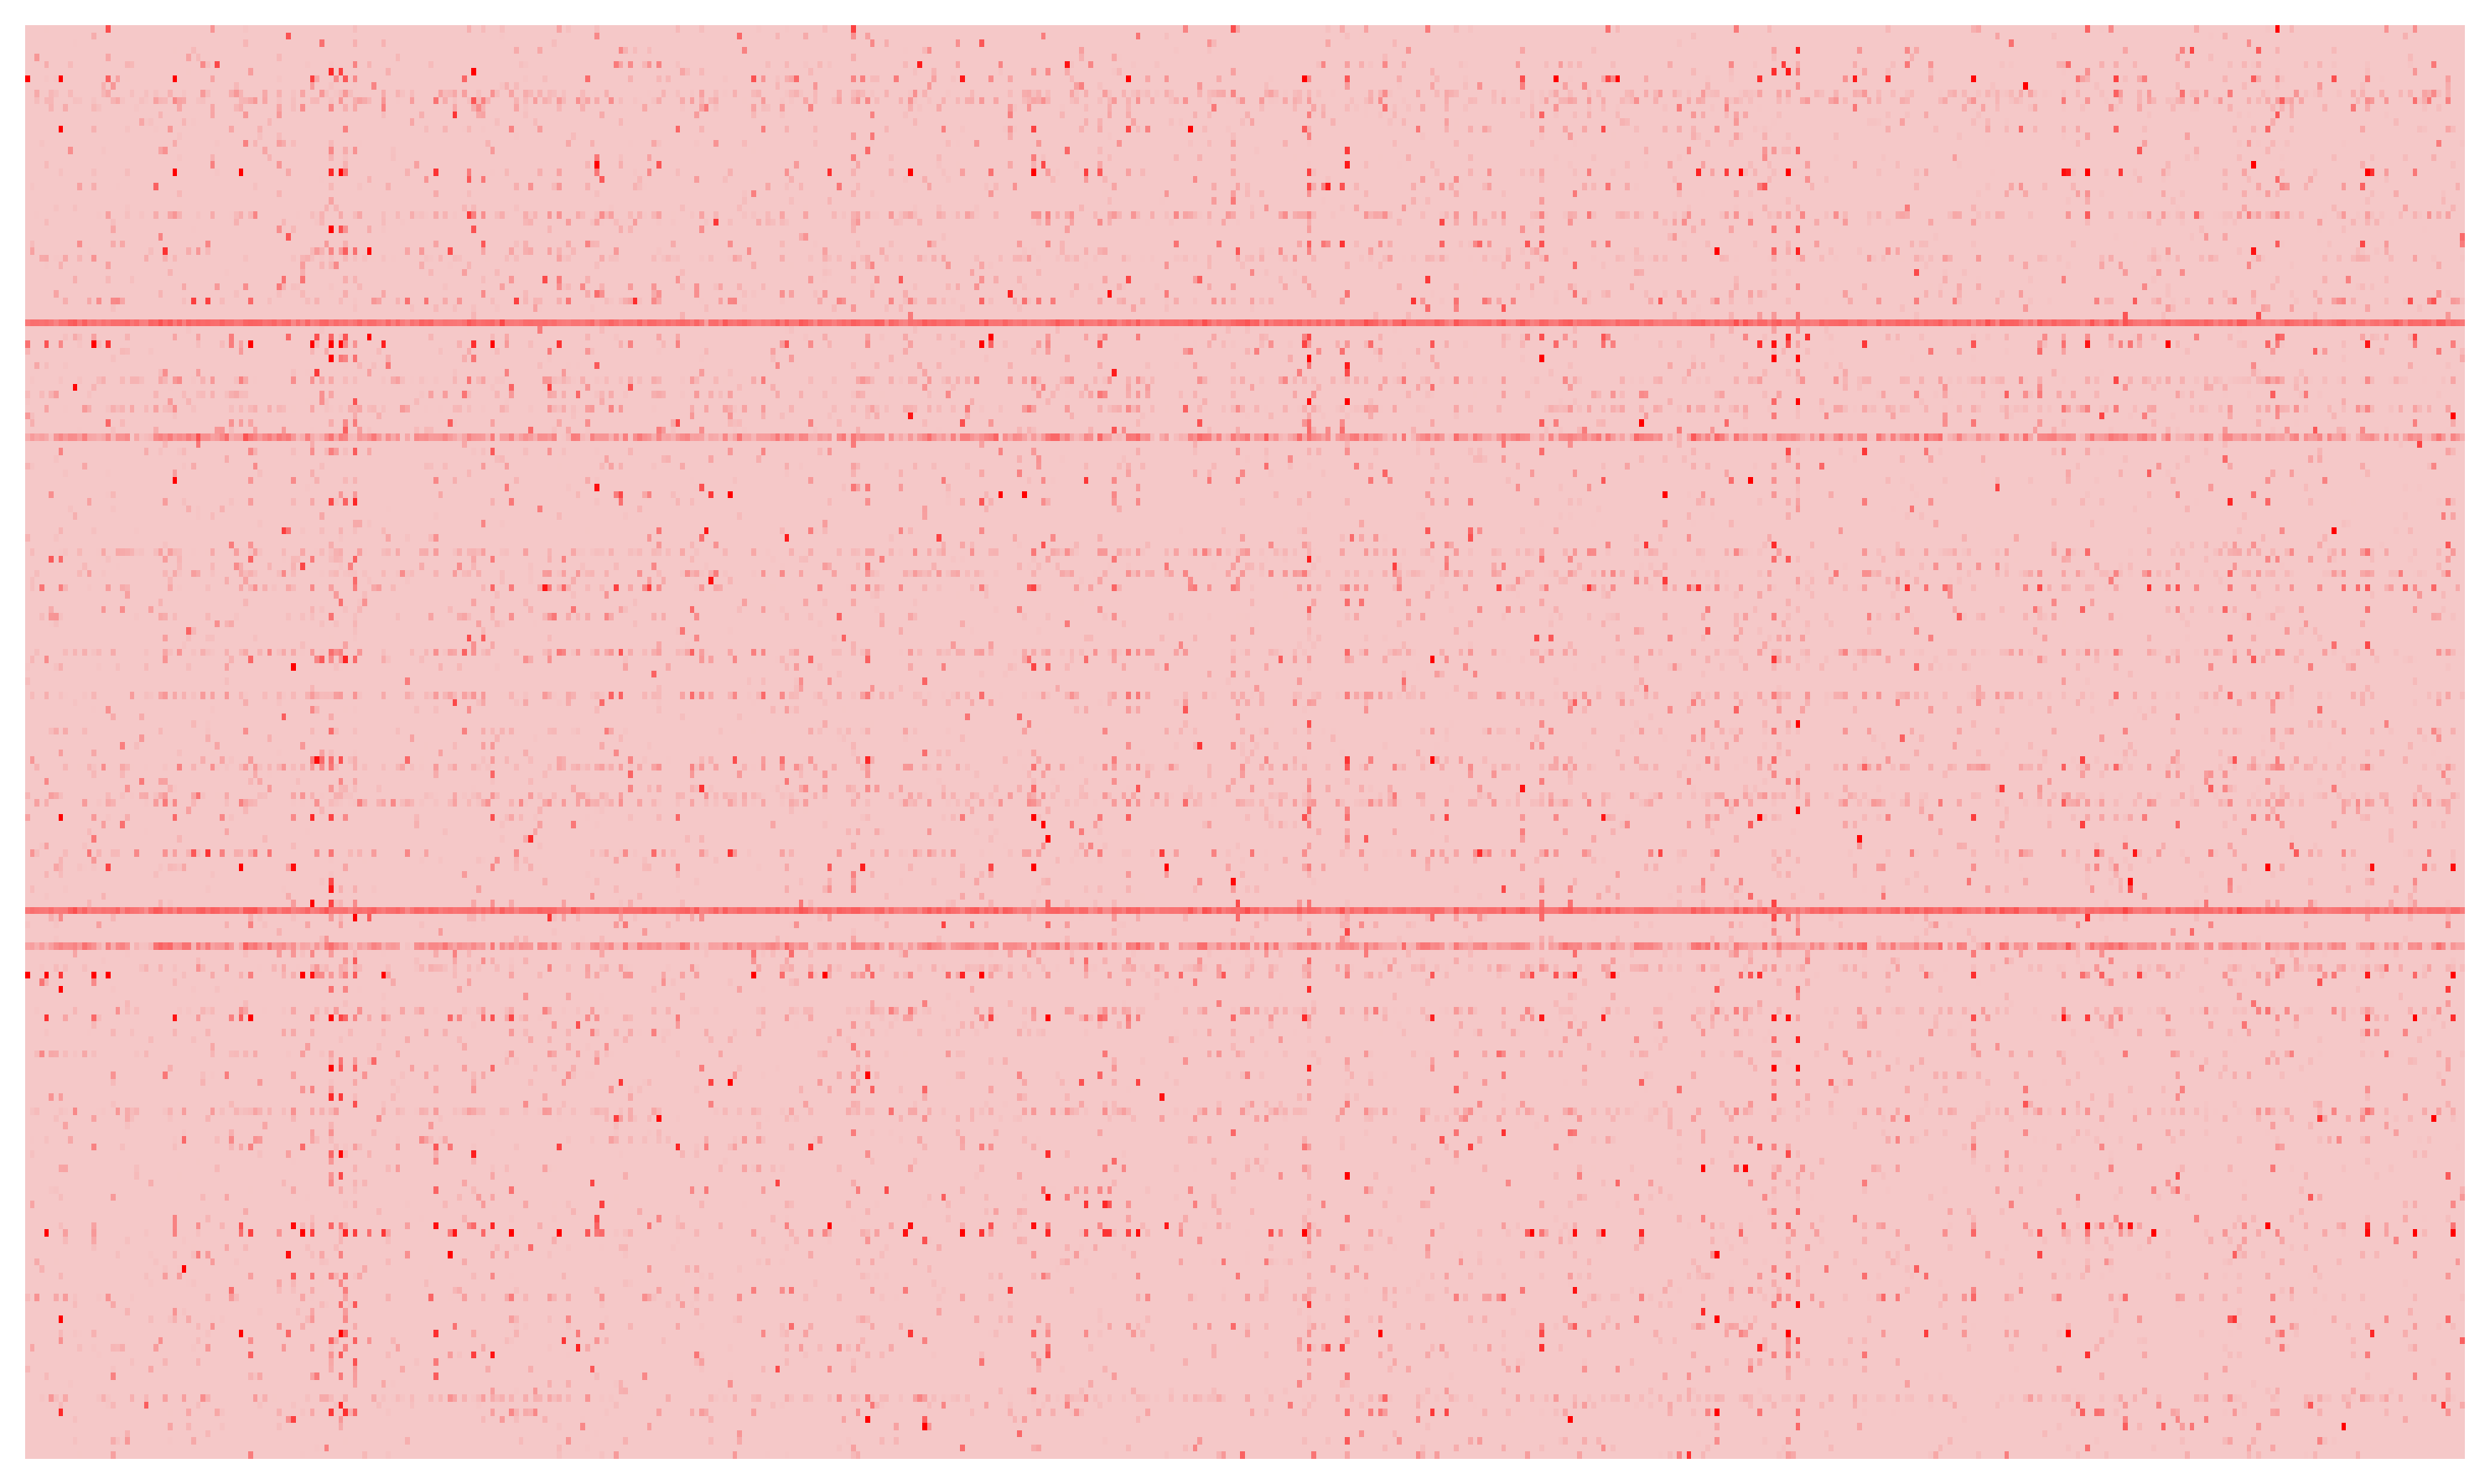

In [21]:
savefig = True

plot_dir = f'{PLOTS_DIR}/v2/schematic/rasters'
os.makedirs(plot_dir, exist_ok=True)

show_cbar = False
n_units = 200
n_imgs = -1

plt.figure(figsize=(10, 6), dpi=300)
sns.heatmap(raster_subject1[:n_units, :n_imgs], cmap=sns.light_palette("royalblue", as_cmap=True), cbar=show_cbar, cbar_kws={'label': 'Z-scored activity'}, vmin=-2.5, vmax=3)
plt.xticks([], [])
plt.yticks([], [])
# plt.xlabel('Image index')
# plt.ylabel('Neuron index')
# plt.title('Raster Plot (Z-scored)')
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/raster_subject1.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

plt.figure(figsize=(10, 6), dpi=300)
arr = raster_subject1[:n_units, :n_imgs]
raster_tmp = arr[:, np.random.permutation(arr.shape[1])][np.random.permutation(arr.shape[0]), :]
sns.heatmap(raster_tmp, cmap=sns.light_palette("red", as_cmap=True), cbar=show_cbar, cbar_kws={'label': 'Z-scored activity'}, vmin=-2.5, vmax=3)
plt.xticks([], [])
plt.yticks([], [])
# plt.xlabel('Image index')
# plt.ylabel('Neuron index')
# plt.title('Raster Plot (Z-scored)')
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/raster_subject1_scrambled.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

plt.figure(figsize=(10, 6), dpi=300)
sns.heatmap(raster_subject2[:n_units, :n_imgs], cmap=sns.light_palette("royalblue", as_cmap=True), cbar=show_cbar, cbar_kws={'label': 'Z-scored activity'}, vmin=-2.5, vmax=3)
plt.xticks([], [])
plt.yticks([], [])
# plt.xlabel('Image index')
# plt.ylabel('Neuron index')
# plt.title('Raster Plot (Z-scored)')
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/raster_subject2.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

plt.figure(figsize=(10, 6), dpi=300)
sns.heatmap(raster_model[:n_units, :n_imgs], cmap=sns.light_palette("red", as_cmap=True), cbar=show_cbar, cbar_kws={'label': 'Z-scored activity'}, vmin=-3, vmax=15)
plt.xticks([], [])
plt.yticks([], [])
# plt.xlabel('Image index')
# plt.ylabel('Neuron index')
# plt.title('Raster Plot (Z-scored)')
plt.tight_layout()
if savefig:
    # plt.savefig(f'{plot_dir}/raster_rn18imgnet_zscored.png', dpi=300, bbox_inches='tight', transparent=True)
    plt.savefig(f'{plot_dir}/raster_{model.name}.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

arr = raster_model[250:250+n_units, :n_imgs] # Randomly taking 200 units after 250
shuffled_raster_model = arr[:, np.random.permutation(arr.shape[1])][np.random.permutation(arr.shape[0]), :]
plt.figure(figsize=(10, 6), dpi=300)
sns.heatmap(shuffled_raster_model, cmap=sns.light_palette("red", as_cmap=True), cbar=show_cbar, cbar_kws={'label': 'Z-scored activity'}, vmin=-3, vmax=15)
plt.xticks([], [])
plt.yticks([], [])
# plt.xlabel('Image index')
# plt.ylabel('Neuron index')
# plt.title('Raster Plot (Z-scored)')
plt.tight_layout()
if savefig:
    # plt.savefig(f'{plot_dir}/raster_rn18imgnet_zscored.png', dpi=300, bbox_inches='tight', transparent=True)
    plt.savefig(f'{plot_dir}/random_raster_{model.name}.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

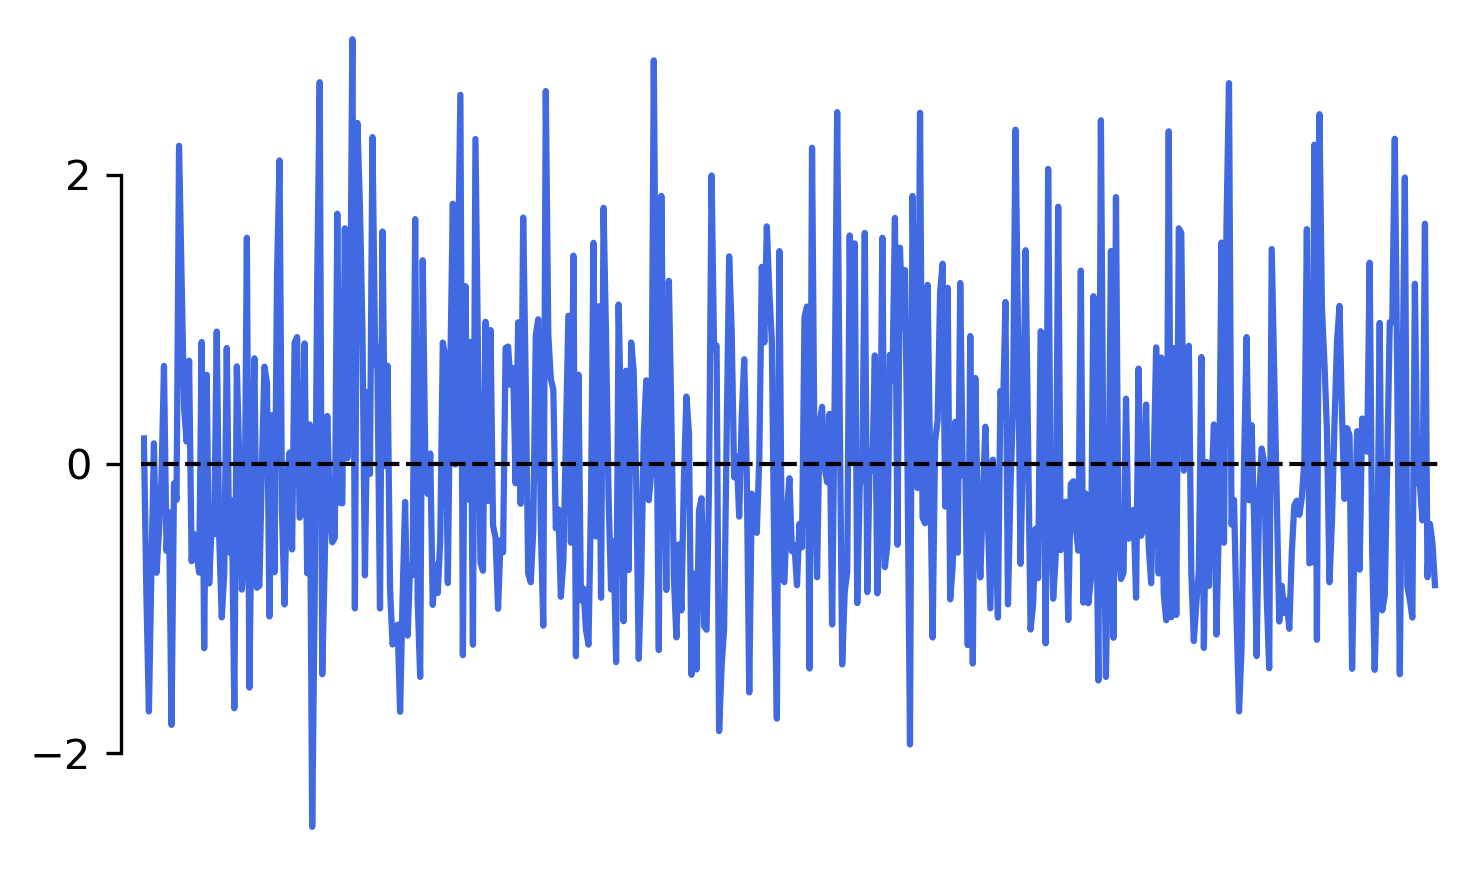

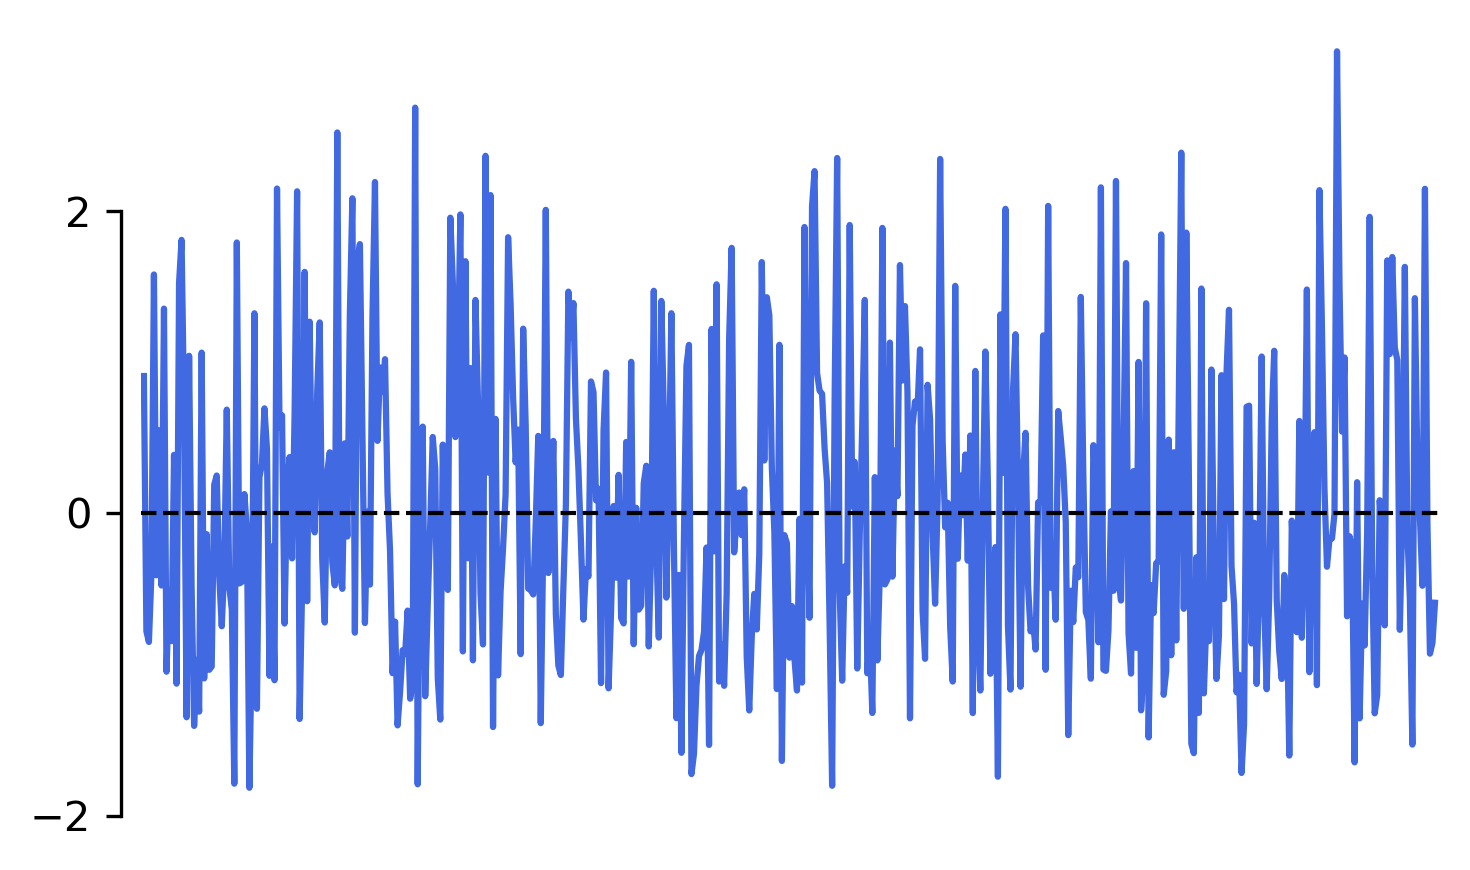

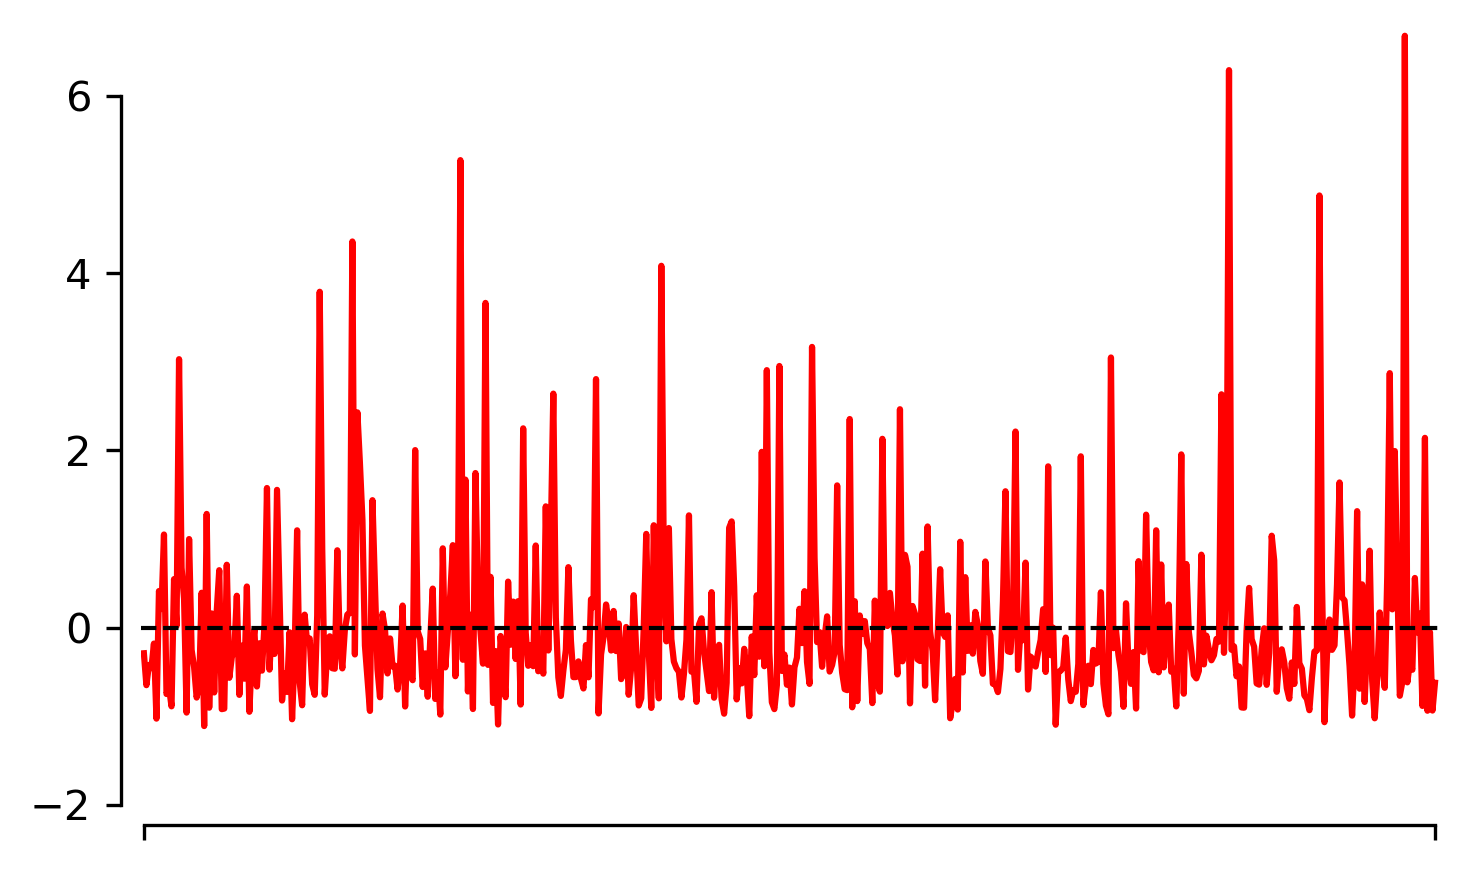

In [234]:
# Subject sorted univariate responses
# plt.figure(figsize=(10, 6), dpi=300)
savefig = True
show_cbar = False

plt.figure(figsize=(5, 3), dpi=300)
plt.plot(subject_data1_zscore, color='royalblue')
plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)
plt.xticks([], [])
plt.yticks([-2, 0, 2])
plt.gca().spines['left'].set_bounds(-2, 2)
plt.xlim(-1, 516)
plt.ylim(-2.6, 3)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/averagedresponse_subject1_zscored.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

plt.figure(figsize=(5, 3), dpi=300)
plt.plot(subject_data2_zscore, color='royalblue')
plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)
plt.xticks([], [])
plt.yticks([-2, 0, 2])
plt.gca().spines['left'].set_bounds(-2, 2)
plt.xlim(-1, 516)
plt.ylim(-2, 3.2)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/averagedresponse_subject2_zscored.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

plt.figure(figsize=(5, 3), dpi=300)
plt.plot(model_data_zscore, color='red')
plt.axhline(y=0, color='black', linestyle='--', alpha=1, linewidth=1)
plt.xticks([0, 514], ['', ''])
plt.gca().spines['bottom'].set_bounds(0, 514)
plt.gca().tick_params(axis='x', which='both', labelleft=False, labelbottom=False)
plt.yticks([-2, 0, 2, 4, 6])
plt.gca().spines['left'].set_bounds(-2, 6)
plt.xlim(-1, 516)
plt.ylim(-2, 6.75)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
# plt.gca().spines['bottom'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/averagedresponse_rn50imgnet_zscored.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

Correlation between subject 2 and subject (5) responses: 0.753
Correlation between subject 2 and model (RN18 ImageNet) responses: 0.605


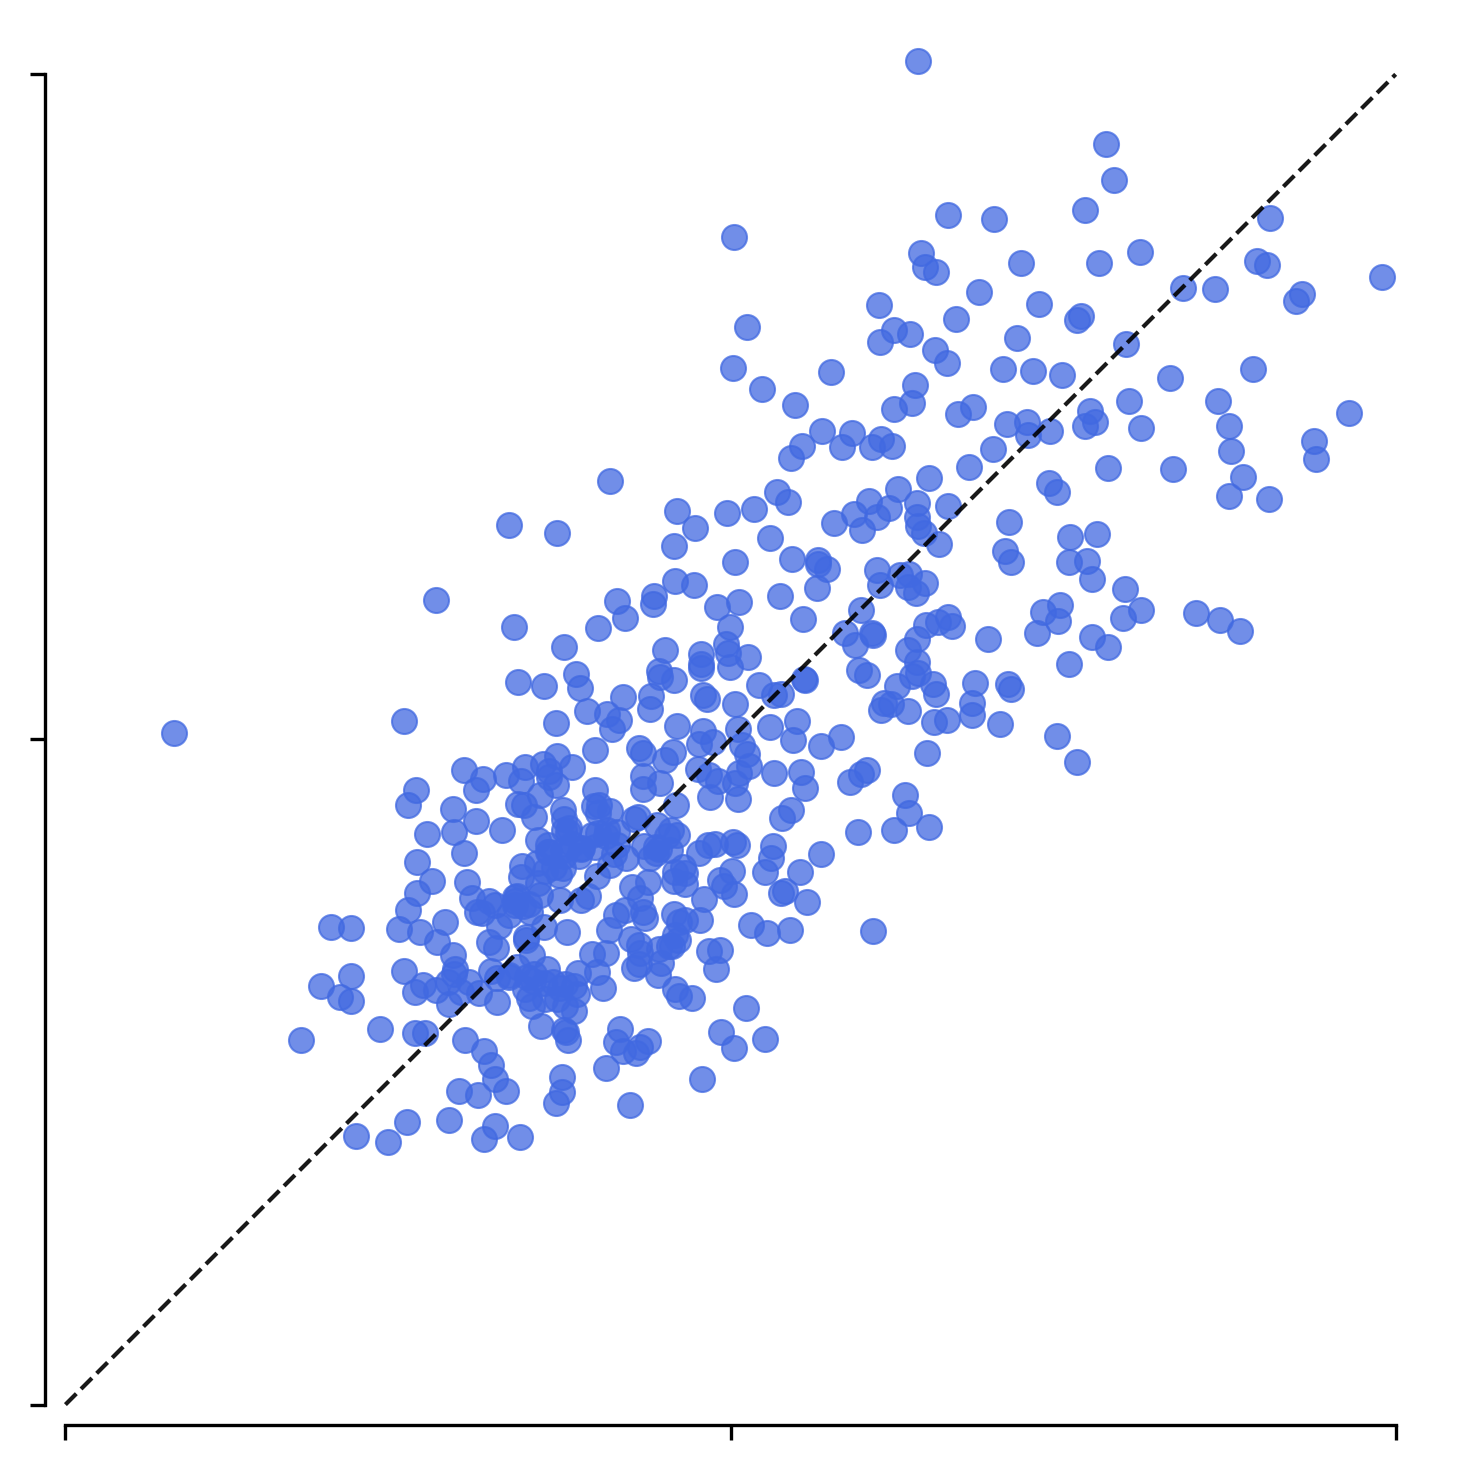

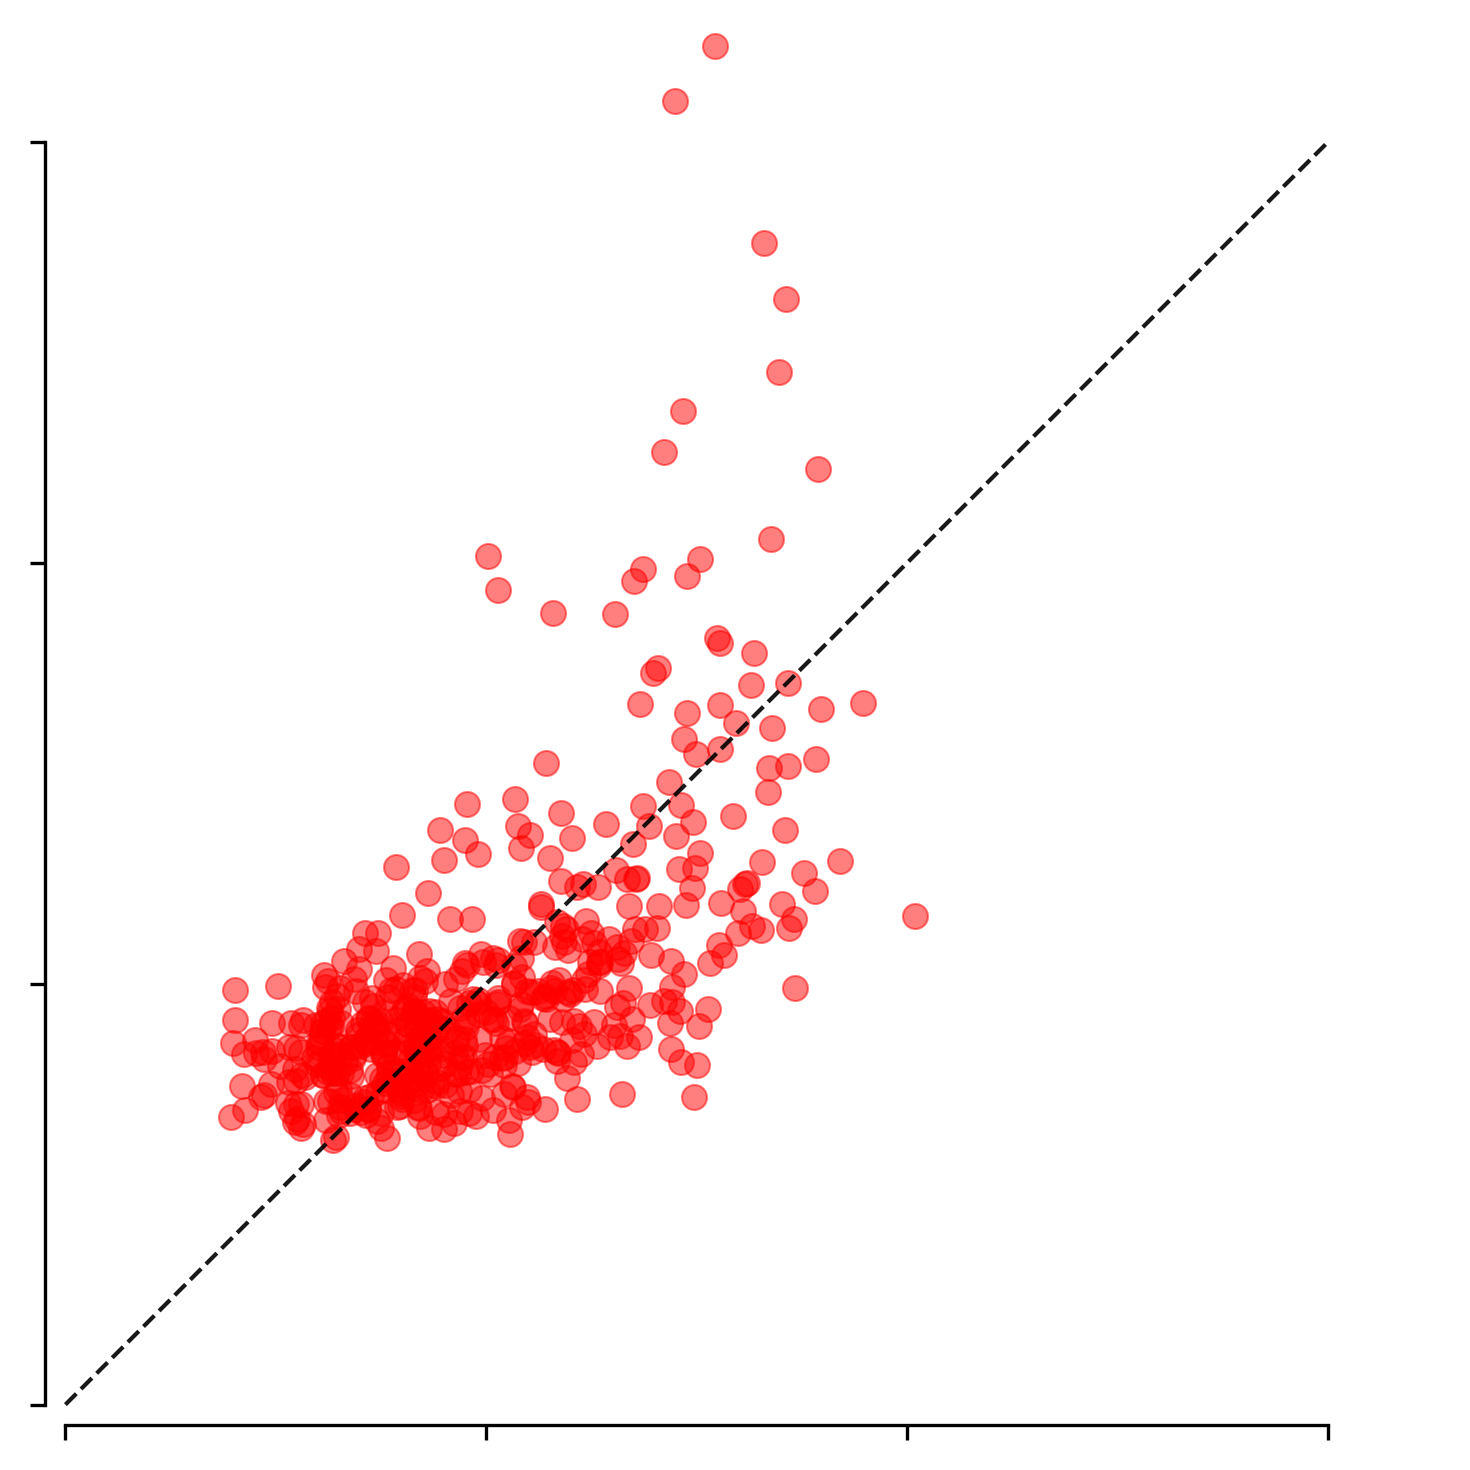

In [239]:
savefig = True
show_cbar = False

subject1_data = subject_data1_zscore
subject2_data = subject_data2_zscore
model_data = model_data_zscore

# Create scatter plot of z-scored responses
plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(subject1_data, subject2_data, alpha=0.75, c='royalblue', linewidths=0.5)

# Calculate correlation (correlation doesn't change with z-scoring)
correlation = np.corrcoef(subject1_data, subject2_data)[0, 1]
print(f'Correlation between subject {subject1} and subject ({subject2}) responses: {correlation:.3f}')

# Limits and axes
plt.xticks([-3, 0, 3])
plt.tick_params(axis='x', labelbottom=False)
plt.gca().spines['bottom'].set_bounds(-3, 3)
plt.xlim(-3, 3.2)
plt.yticks([-3, 0, 3])
plt.tick_params(axis='y', labelleft=False)
plt.gca().spines['left'].set_bounds(-3, 3)
plt.ylim(-3, 3.2)
x_range = np.linspace(-3, 3, 100)
plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=False)

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/subject{subject2}y_subject{subject1}x_pearsonr.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()

# Create scatter plot of z-scored responses
plt.figure(figsize=(5, 5), dpi=300)
plt.scatter(subject2_data, model_data, alpha=0.5, c='red', linewidths=0.5)

# Calculate correlation (correlation doesn't change with z-scoring)
correlation = np.corrcoef(subject2_data, model_data)[0, 1]
print(f'Correlation between subject {subject1} and model (RN18 ImageNet) responses: {correlation:.3f}')

# Limits and axes
plt.xticks([-3, 0, 3, 6])
plt.tick_params(axis='x', labelbottom=False)
plt.gca().spines['bottom'].set_bounds(-3, 6)
plt.xlim(-3, 6.8)
plt.yticks([-3, 0, 3, 6])
plt.tick_params(axis='y', labelleft=False)
plt.gca().spines['left'].set_bounds(-3, 6)
plt.ylim(-3, 6.8)
x_range = np.linspace(-3, 6, 100)
plt.plot(x_range, x_range, 'k--', alpha=0.9, linewidth=1, clip_on=False)

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))

plt.tight_layout()
if savefig:
    plt.savefig(f'{plot_dir}/subject{subject2}y_{model.name}_pearsonr.png', dpi=300, bbox_inches='tight', transparent=True)
else:
    plt.show()